# 02 – Demand model (Zurich city load, day-ahead, 4-hour blocks)

Loads the outputs of `python -m src.models.demand` and shows the key tables and figures. Details and the plain-language summary: `reports/model_notes_demand.md`.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..'))
os.chdir(os.path.abspath('..'))
import pandas as pd, joblib
from IPython.display import Image, display
import src.models.common as common
pd.set_option('display.precision', 3)

## Overall metrics (MW; MAPE in %)

In [2]:
met = pd.read_csv('reports/metrics_demand.csv', dtype={'block': str})
allm = met[met.block == 'all']
allm.pivot_table(index='model', columns='split', values=['mae', 'mape_or_smape']).reindex(['naive', 'linear', 'rf', 'gbm', 'best'])

mae               mape_or_smape              
split  rolling   test    val       rolling   test    val
model                                                   
naive   15.055  9.581  9.031         4.959  3.125  3.030
linear   5.638  4.543  4.781         1.849  1.509  1.634
rf       6.983  5.791  5.806         2.296  1.919  1.982
gbm      5.280  4.081  3.932         1.724  1.347  1.365
best     4.647  3.362  3.202         1.505  1.116  1.078

## Test month (October 2026) with day-clustered bootstrap 95 % CI for the MAE

In [3]:
allm[allm.split == 'test'][['model', 'mae', 'rmse', 'mape_or_smape', 'bias', 'mae_ci_low', 'mae_ci_high']]

,model,mae,rmse,mape_or_smape,bias,mae_ci_low,mae_ci_high
70,naive,9.581,13.497,3.125,-4.169,7.360,12.231
77,linear,4.543,6.001,1.509,0.644,3.814,5.282
84,rf,5.791,7.984,1.919,-1.621,4.872,6.908
91,gbm,4.081,5.527,1.347,0.309,3.497,4.726
98,best,3.362,4.638,1.116,0.484,2.918,3.901


## MAE per block, test month

In [4]:
met[(met.split == 'test') & (met.block != 'all')].pivot(index='block', columns='model', values='mae')

model,best,gbm,linear,naive,rf
block,,,,,
0,1.356,1.674,1.938,4.302,1.962
1,1.731,2.380,2.475,6.037,4.092
2,5.131,5.939,6.993,12.100,8.101
3,4.700,5.767,6.696,13.698,9.146
4,4.211,4.919,5.499,12.247,6.679
5,3.044,3.805,3.654,9.105,4.763


## Diebold–Mariano tests (daily MAE; negative mean_diff = best is better)

In [5]:
pd.read_csv('reports/model_tests_demand.csv')

,target,split,model_a,model_b,loss,mean_diff,dm_stat,p_value,n_days
0,demand,val,best,naive,daily mean absolute error,-5.829,-4.738,5.256e-05,30
1,demand,val,best,gbm,daily mean absolute error,-0.730,-3.927,4.870e-04,30
2,demand,test,best,naive,daily mean absolute error,-6.219,-3.048,4.774e-03,31
3,demand,test,best,gbm,daily mean absolute error,-0.718,-1.907,6.609e-02,31
4,demand,rolling,best,naive,daily mean absolute error,-10.408,-8.180,6.005e-15,335
5,demand,rolling,best,gbm,daily mean absolute error,-0.633,-3.157,1.740e-03,335


## Forecast vs actual, October 2026

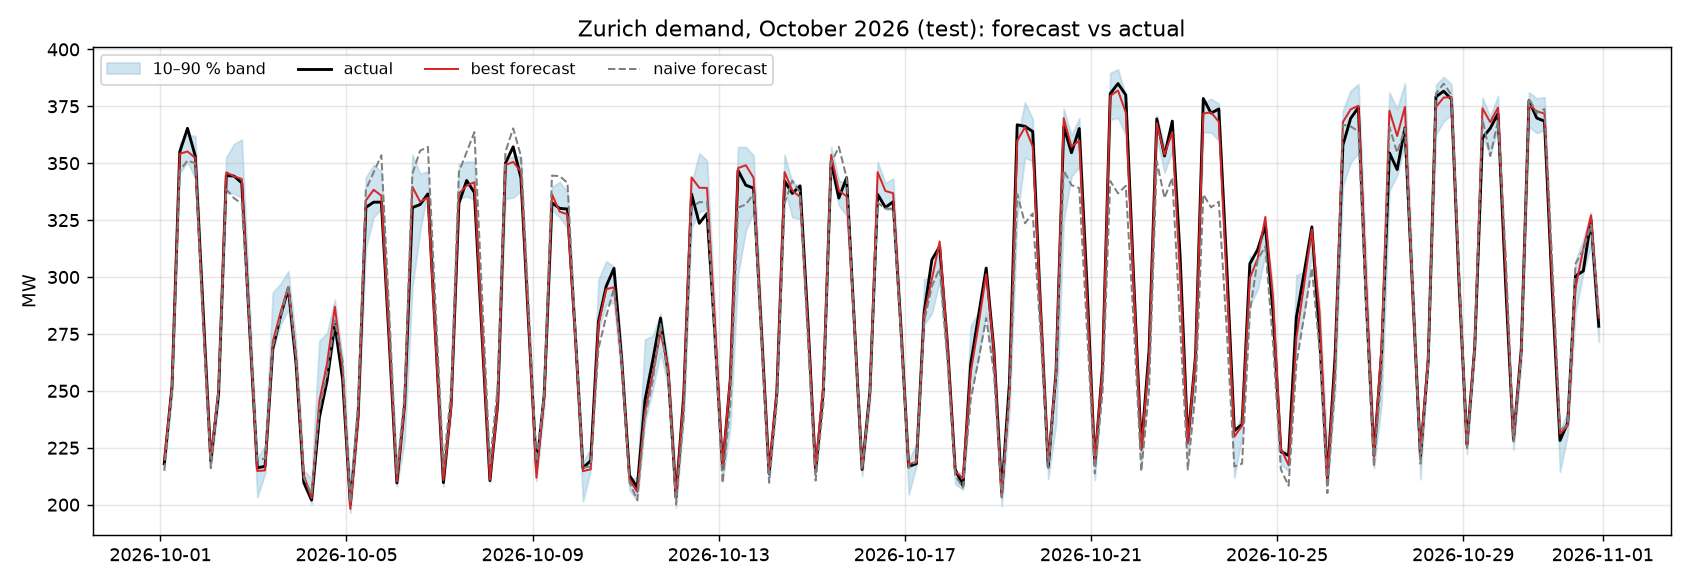

In [6]:
display(Image('reports/figures/demand_test_forecast_vs_actual.png'))

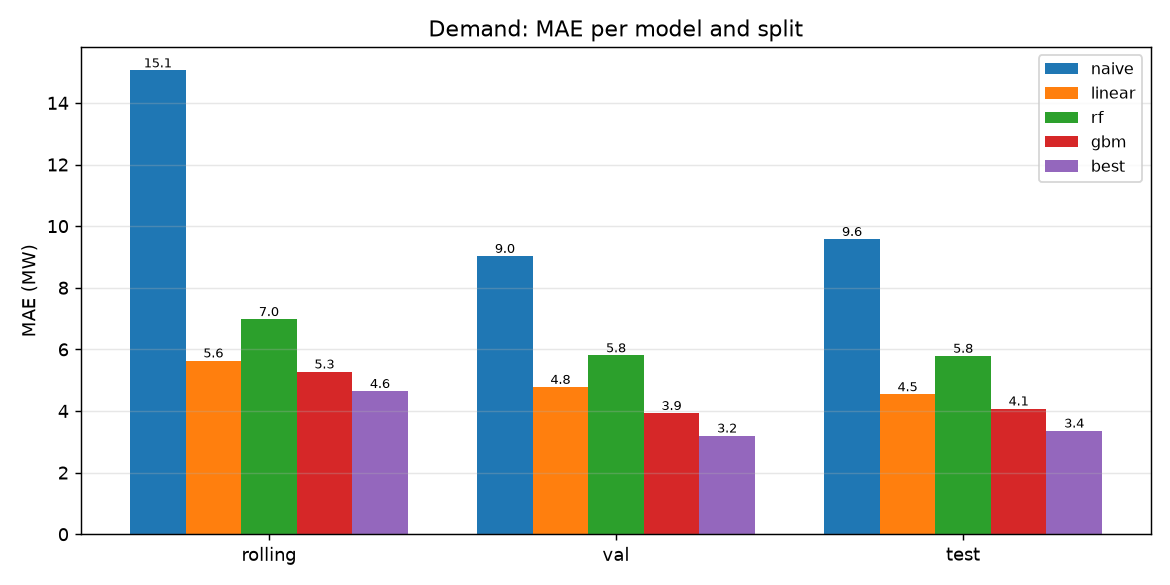

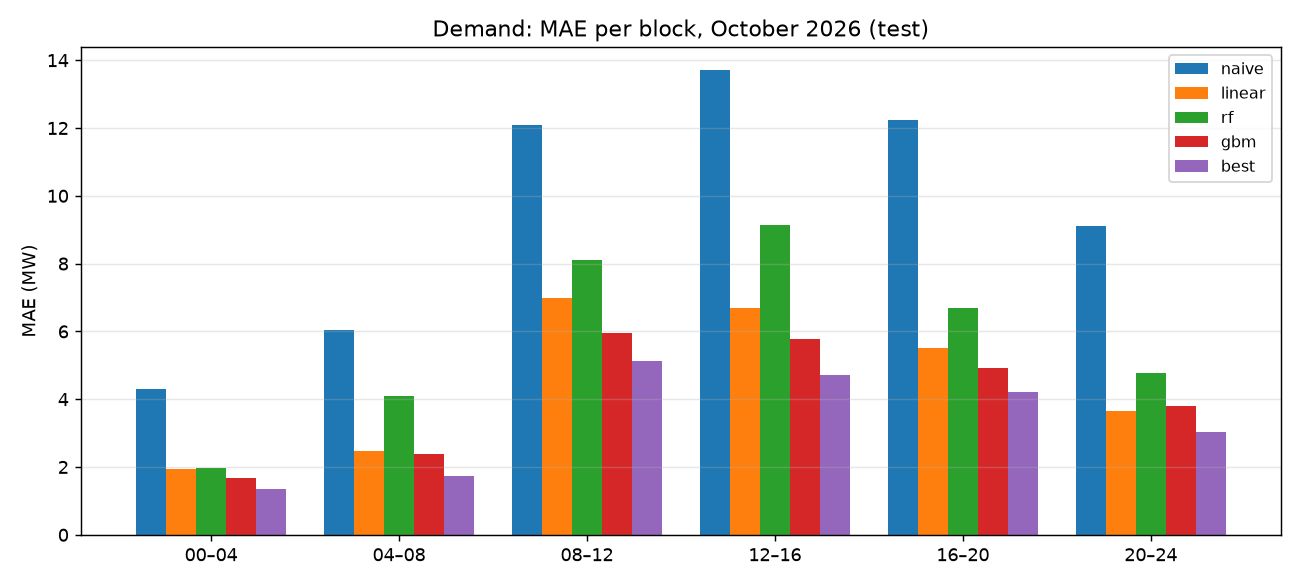

In [7]:
display(Image('reports/figures/demand_model_ladder.png'))
display(Image('reports/figures/demand_error_by_block.png'))

## Prediction band coverage (should be about 80 % inside the 10–90 % band)

In [8]:
pr = pd.read_parquet('reports/predictions_demand.parquet')
pr['inside'] = (pr.y_true >= pr.pred_q10) & (pr.y_true <= pr.pred_q90)
pr.groupby('split').inside.mean()

split
rolling    0.729
test       0.785
val        0.756
Name: inside, dtype: float64

## Drivers (permutation importance on Sep + Oct 2026)

,feature,mae_increase,std,base_mae
0,past demand (all lags),47.234,1.377,3.283
1,weekday / weekend,12.284,1.159,3.283
2,holidays and school holidays,9.454,0.946,3.283
3,weather (forecast + past observed),6.997,0.486,3.283
4,"season (month, day of year, daylight)",0.153,0.019,3.283
5,Swiss solar (lagged),0.027,0.012,3.283
6,EVs and charging,0.001,0.001,3.283
7,COVID stringency,0.000,0.000,3.283
8,events and football,-0.015,0.004,3.283


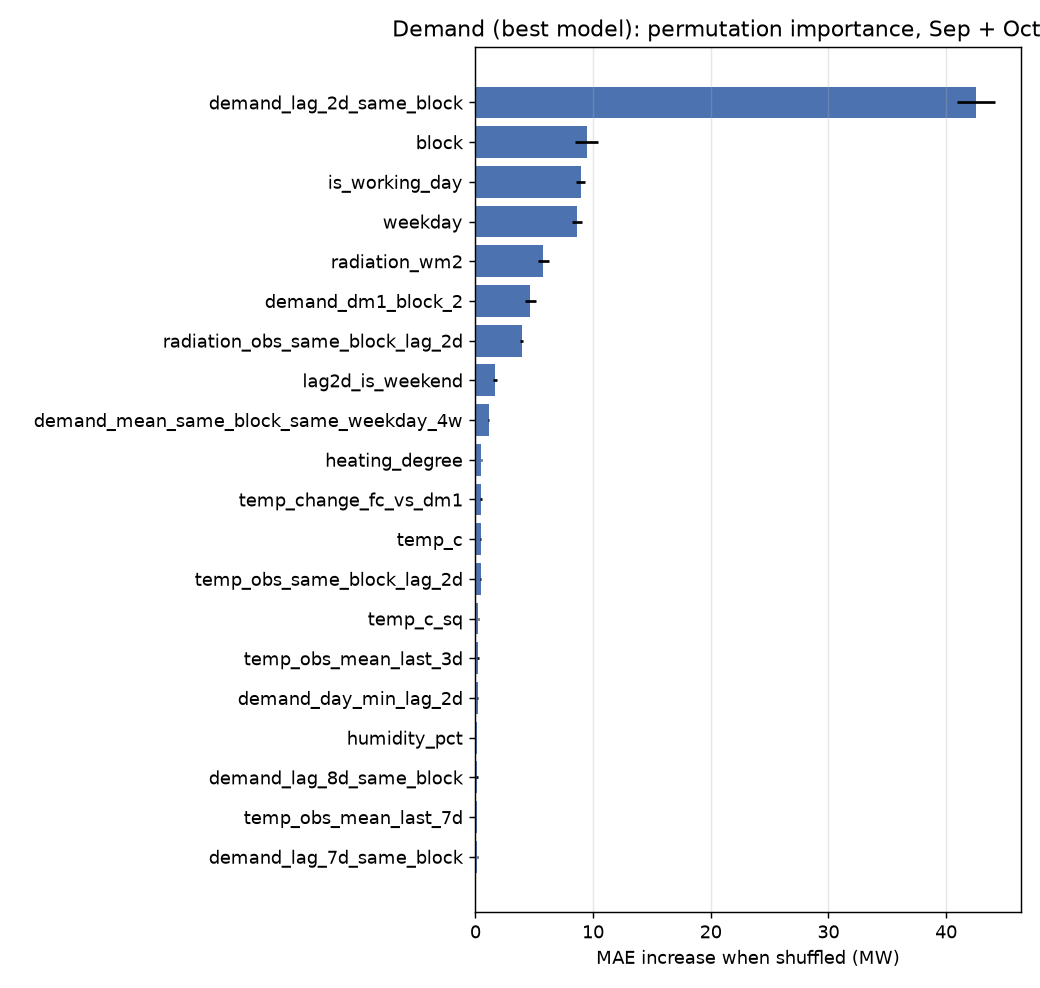

In [9]:
display(pd.read_csv('reports/importance_groups_demand.csv'))
display(Image('reports/figures/demand_permutation_importance.png'))

## What was tried (September 2026 and time-series CV)

In [10]:
pd.read_csv('reports/experiments_demand.csv')

,experiment,kind,val_mae,val_mape,val_bias,cv_mae,cv_mae_last2,test_mae,test_mape
0,A LightGBM log-ratio vs 2-day lag (1 seed),variant,3.292,1.116,-0.239,4.606,4.613,NaN,NaN
1,A0 LightGBM on the level,variant,3.848,1.338,-0.791,6.406,4.999,NaN,NaN
2,A1 log-ratio vs 7-day lag,variant,3.898,1.363,-0.981,5.876,5.594,NaN,NaN
3,A2 difference vs 2-day lag,variant,3.422,1.170,-0.348,4.593,4.629,NaN,NaN
4,A3 difference vs 4-week same-weekday mean,variant,3.947,1.409,-1.276,6.738,5.603,NaN,NaN
5,B1 L1 loss,variant,3.313,1.129,-0.329,4.883,4.948,NaN,NaN
6,B2 Huber loss,variant,3.187,1.082,-0.975,4.784,4.720,NaN,NaN
7,C1 recency half-life 1 y,variant,4.064,1.400,-0.246,4.759,4.831,NaN,NaN
8,C2 recency half-life 2 y,variant,3.450,1.169,0.082,4.664,4.687,NaN,NaN
9,C3 recency half-life 3 y,variant,3.384,1.145,0.303,4.639,4.649,NaN,NaN


## The saved model predicts any rows of features.parquet

In [11]:
m = joblib.load('models/demand_best.joblib')
oct_rows = common.split_frame(common.load_features(), 'test')
out = oct_rows[['delivery_date', 'block', 'demand_mw']].copy()
out['forecast'] = m.predict(oct_rows)
out.head(12)

,delivery_date,block,demand_mw,forecast
16896,2026-10-01,0,217.977,219.760
16897,2026-10-01,1,251.854,251.907
16898,2026-10-01,2,354.958,354.148
16899,2026-10-01,3,365.312,355.154
16900,2026-10-01,4,353.125,352.313
16901,2026-10-01,5,285.866,283.430
16902,2026-10-02,0,219.124,220.436
16903,2026-10-02,1,248.650,251.254
16904,2026-10-02,2,344.546,345.992
16905,2026-10-02,3,344.353,344.231
